In [41]:
# --- Section 1: All Necessary Imports ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from scipy.stats import multivariate_normal
from sklearn.metrics import silhouette_score
from kneed import KneeLocator

In [42]:

# --- Section 2: Data and Preprocessing ---

# Define the path to your local CSV file
filepath = 'Clustering_dataset.csv'

# Load the dataset from the file
df = pd.read_csv(filepath)

print("--- Data Loaded from File ---")
print(df.head())

# Handle missing values by creating a cleaned copy
df_cleaned = df.dropna().copy()

# Select the numerical features for clustering
features = df_cleaned[['Age', 'Annual_Income', 'Spending_Score']]

# Scale the selected features
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features) # Shape: (n_samples, n_features)

# Create the transposed version needed for our custom MyKMeans class
scaled_features_transposed = scaled_features.T # Shape: (n_features, n_samples)

print("\nData is cleaned and scaled.")
print("Shape of scaled_features:", scaled_features.shape)
print("Shape of scaled_features_transposed:", scaled_features_transposed.shape)



--- Data Loaded from File ---
   CustomerID  Gender   Age  Annual_Income  Spending_Score
0           1    Male  19.0           15.0            39.0
1           2    Male  21.0            NaN            81.0
2           3  Female  20.0           16.0             6.0
3           4  Female  23.0           16.0            77.0
4           5  Female  31.0           17.0            40.0

Data is cleaned and scaled.
Shape of scaled_features: (178, 3)
Shape of scaled_features_transposed: (3, 178)


In [43]:



# --- Section 3: MyKMeans Class Definition ---
class MyKMeans:
    """A from-scratch implementation of the K-Means clustering algorithm."""
    def __init__(self, k, max_iters=100):
        self.k = k
        self.max_iters = max_iters
        self.centroids_ = None

    def _get_cluster_labels(self, X):
        diff = X[:, :, np.newaxis] - self.centroids_[:, np.newaxis, :]
        distances_sq = np.sum(diff**2, axis=0)
        return np.argmin(distances_sq, axis=1)

    def fit(self, X):
        n_features, n_samples = X.shape
        random_indices = np.random.choice(n_samples, self.k, replace=False)
        self.centroids_ = X[:, random_indices]
        for _ in range(self.max_iters):
            old_centroids = self.centroids_.copy()
            labels = self._get_cluster_labels(X)
            new_centroids = np.array([X[:, labels == i].mean(axis=1) for i in range(self.k)]).T
            self.centroids_ = new_centroids
            if np.all(old_centroids == self.centroids_):
                break
        return self

    def predict(self, X):
        if self.centroids_ is None:
            raise RuntimeError("The model has not been fitted yet. Please call fit() first.")
        return self._get_cluster_labels(X)

    def getCost(self, X):
        cost = 0
        labels = self.predict(X)
        for i in range(self.k):
            cluster_points = X[:, labels == i]
            if cluster_points.shape[1] > 0:
                centroid = self.centroids_[:, i].reshape(-1, 1)
                cost += np.sum((cluster_points - centroid)**2)
        return cost

print("\nMyKMeans class defined.")




MyKMeans class defined.


In [44]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler # Added for a runnable example
from sklearn.datasets import make_blobs # Added for a runnable example
import pandas as pd # Added for a runnable example

class MyGMM:
    """
    A from-scratch implementation of the Gaussian Mixture Model (GMM)
    using the Expectation-Maximization (EM) algorithm.
    """
    def __init__(self, k, max_iters=100, tol=1e-4):
        self.k = k
        self.max_iters = max_iters
        self.tol = tol
        self.d = None # Will be set in fit()
        
        # Learned parameters
        self.weights_ = None
        self.means_ = None
        self.covariances_ = None
        
        # Results
        self.responsibilities_ = None
        self.log_likelihood_ = -np.inf
        self.log_likelihood_history_ = []

    def fit(self, X):
        """
        Trains the GMM model on the dataset X using the EM algorithm.
        """
        n_samples, n_features = X.shape
        self.d = n_features  # <-- KEY CHANGE: Determine dimensions from data

        # --- 1. Initialization Step ---
        kmeans = KMeans(n_clusters=self.k, n_init='auto', random_state=42)
        kmeans.fit(X)
        self.means_ = kmeans.cluster_centers_
        self.covariances_ = np.array([np.eye(self.d)] * self.k)
        self.weights_ = np.ones(self.k) / self.k
        
        # --- 2. The EM Algorithm Loop ---
        for i in range(self.max_iters):
            # --- E-Step ---
            self.responsibilities_ = self._calculate_responsibilities(X)

            # --- M-Step ---
            nk = np.sum(self.responsibilities_, axis=0)
            self.weights_ = nk / n_samples
            self.means_ = (self.responsibilities_.T @ X) / nk[:, np.newaxis]
            
            for j in range(self.k):
                diff = X - self.means_[j]
                # Use self.d which is now correctly set
                cov_j = (self.responsibilities_[:, j, np.newaxis] * diff).T @ diff / nk[j]
                # Add regularization
                self.covariances_[j] = cov_j + np.eye(self.d) * 1e-6

            # --- Calculate Log-Likelihood & Check for Convergence ---
            new_log_likelihood = self._get_log_likelihood(X)
            self.log_likelihood_history_.append(new_log_likelihood)
            
            if i > 0 and abs(new_log_likelihood - self.log_likelihood_) < self.tol:
                break
            self.log_likelihood_ = new_log_likelihood
            
        return self

    def _calculate_responsibilities(self, X):
        """Helper function for the E-Step."""
        likelihoods = np.zeros((X.shape[0], self.k))
        for i in range(self.k):
            distribution = multivariate_normal(mean=self.means_[i], cov=self.covariances_[i], allow_singular=True)
            likelihoods[:, i] = distribution.pdf(X)
        
        numerator = likelihoods * self.weights_
        denominator = np.sum(numerator, axis=1, keepdims=True)
        return numerator / (denominator + 1e-20) # Avoid division by zero

    def _get_log_likelihood(self, X):
        """Helper function to calculate log-likelihood."""
        likelihoods = np.zeros((X.shape[0], self.k))
        for i in range(self.k):
            distribution = multivariate_normal(mean=self.means_[i], cov=self.covariances_[i], allow_singular=True)
            likelihoods[:, i] = distribution.pdf(X)
        
        return np.sum(np.log(np.sum(likelihoods * self.weights_, axis=1) + 1e-20))

    def getMembership(self):
        """Returns the final responsibilities matrix."""
        if self.responsibilities_ is None:
            raise RuntimeError("Model has not been fitted. Call fit() first.")
        return self.responsibilities_

    def getLikelihood(self):
        """Returns the final log-likelihood value."""
        if not self.log_likelihood_history_:
             raise RuntimeError("Model has not been fitted. Call fit() first.")
        return self.log_likelihood_history_[-1]

    def drawLikelihood(self):
        """Plots the log-likelihood convergence over iterations."""
        if not self.log_likelihood_history_:
            raise RuntimeError("Model has not been fitted. Call fit() first.")
        
        plt.figure(figsize=(10, 6))
        plt.plot(range(len(self.log_likelihood_history_)), self.log_likelihood_history_, marker='o')
        plt.title('GMM Log-Likelihood Convergence')
        plt.xlabel('Iteration')
        plt.ylabel('Log-Likelihood')
        plt.grid(True)
        plt.show()
    
    def predict(self, X):
        """Predicts the cluster label for each sample in X."""
        responsibilities = self._calculate_responsibilities(X)
        return np.argmax(responsibilities, axis=1)

Final Log-Likelihood: -603.9598

Showing the Log-Likelihood convergence plot...


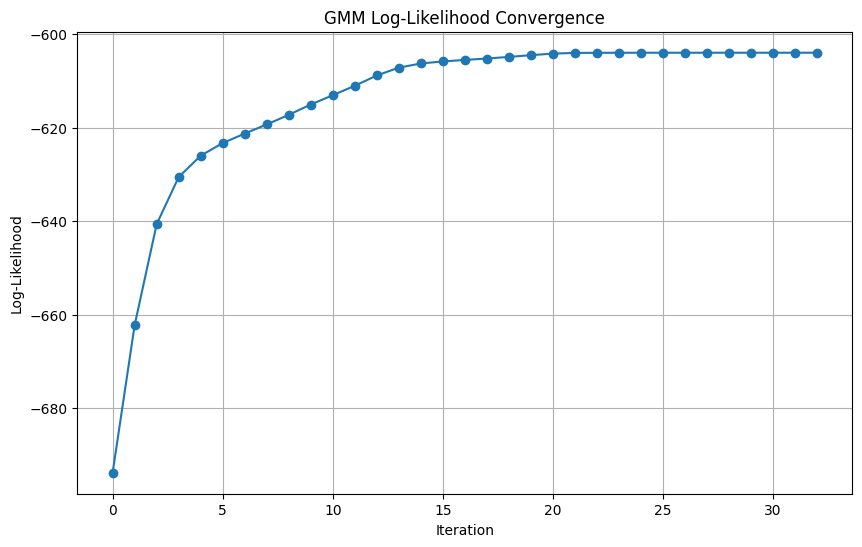


Shape of the membership matrix: (178, 5)

--- DataFrame with GMM Clusters ---
   CustomerID  Gender   Age  Annual_Income  Spending_Score  GMM_Cluster
0           1    Male  19.0           15.0            39.0            4
2           3  Female  20.0           16.0             6.0            0
3           4  Female  23.0           16.0            77.0            2
4           5  Female  31.0           17.0            40.0            4
5           6  Female  22.0           17.0            76.0            2


In [45]:
# Assume 'scaled_features' is your (n_samples, 3) data
# Assume 'df_cleaned' is your DataFrame with no NaNs

# Instantiate and fit your GMM model
gmm = MyGMM(k=5, max_iters=100) # Using k=5 as an example
gmm.fit(scaled_features)

# Get the final log-likelihood
final_likelihood = gmm.getLikelihood()
print(f"Final Log-Likelihood: {final_likelihood:.4f}")

# Draw the convergence plot
print("\nShowing the Log-Likelihood convergence plot...")
gmm.drawLikelihood()

# Get the soft cluster assignments (memberships)
memberships = gmm.getMembership()
print(f"\nShape of the membership matrix: {memberships.shape}")

# Get the hard cluster assignments
labels = gmm.predict(scaled_features)

# Add the GMM cluster labels back to your DataFrame
df_cleaned['GMM_Cluster'] = labels
print("\n--- DataFrame with GMM Clusters ---")
print(df_cleaned.head())

Running BIC Method with custom GMM...
  BIC for k=2: 1483.91
  BIC for k=3: 1465.98
  BIC for k=4: 1445.61
  BIC for k=5: 1461.83
  BIC for k=6: 1460.51
  BIC for k=7: 1494.50
  BIC for k=8: 1516.96
  BIC for k=9: 1541.61
  BIC for k=10: 1571.39


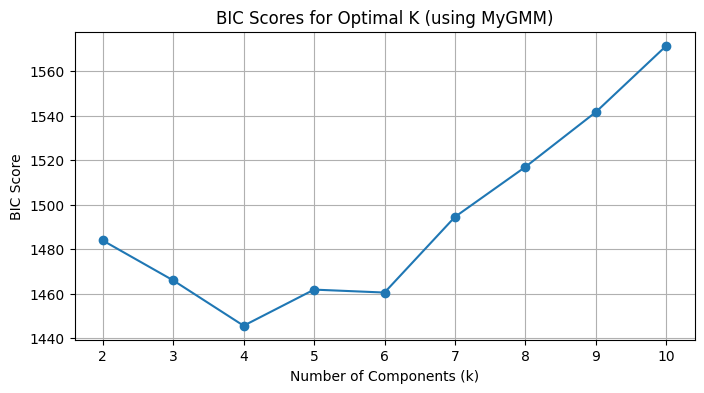

In [46]:
import numpy as np
import matplotlib.pyplot as plt

# Assume 'MyGMM' class is defined
# Assume 'scaled_features' is your (n_samples, n_features) data

bic_scores = []
k_range = range(2, 11)

print("Running BIC Method with custom GMM...")
for k in k_range:
    # 1. Create and fit your custom MyGMM
    gmm = MyGMM(k=k, max_iters=100, tol=1e-4)
    gmm.fit(scaled_features)
    
    # --- 2. Manually Calculate BIC ---
    # Get log-likelihood from your custom method
    log_likelihood = gmm.getLikelihood()
    
    # Get data dimensions
    n_samples, n_features = scaled_features.shape
    
    # Calculate the total number of free parameters
    # Means: k * n_features
    # Covariances: k * n_features * (n_features + 1) / 2
    # Weights: k - 1
    n_params = (k * n_features) + (k * n_features * (n_features + 1) / 2) + (k - 1)
    
    # Calculate BIC
    bic_score = n_params * np.log(n_samples) - 2 * log_likelihood
    bic_scores.append(bic_score)
    
    print(f"  BIC for k={k}: {bic_score:.2f}")

# 3. Plot the BIC scores
plt.figure(figsize=(8, 4))
plt.plot(k_range, bic_scores, marker='o', linestyle='-')
plt.title('BIC Scores for Optimal K (using MyGMM)')
plt.xlabel('Number of Components (k)')
plt.ylabel('BIC Score')
plt.xticks(k_range)
plt.grid(True)
plt.show()

* Commentary on the Optimal Value of K (BIC Method)

    According to the Bayesian Information Criterion (BIC), the optimal number of clusters (or components) for this dataset is **k=4**.

    This conclusion is drawn by identifying the number of clusters that corresponds to the **lowest BIC score**. The BIC is a model selection criterion that penalizes model complexity; therefore, a lower score indicates a better balance between how well the model fits the data and how simple the model is.

    * **Analysis of the Plot:** The graph clearly shows a "valley" or a distinct minimum point. The BIC score decreases from `k=2` to `k=4`, reaching its lowest value at **k=4** (approximately 1445).
    * **For k > 4:** The BIC score begins to rise steadily. This indicates that while adding more clusters might slightly improve the model's fit to the data, the penalty for the added complexity (more parameters for each new Gaussian component) outweighs the benefit. The model becomes unnecessarily complex for the underlying structure of the data.

    Therefore, the BIC method suggests that a model with **4 components** provides the most optimal and parsimonious description of the customer data.


Running Silhouette Method with custom GMM...
  Silhouette Score for k=2: 0.3275
  Silhouette Score for k=3: 0.3315
  Silhouette Score for k=4: 0.3673
  Silhouette Score for k=5: 0.2991
  Silhouette Score for k=6: 0.3438
  Silhouette Score for k=7: 0.3061
  Silhouette Score for k=8: 0.2793
  Silhouette Score for k=9: 0.2909
  Silhouette Score for k=10: 0.2868


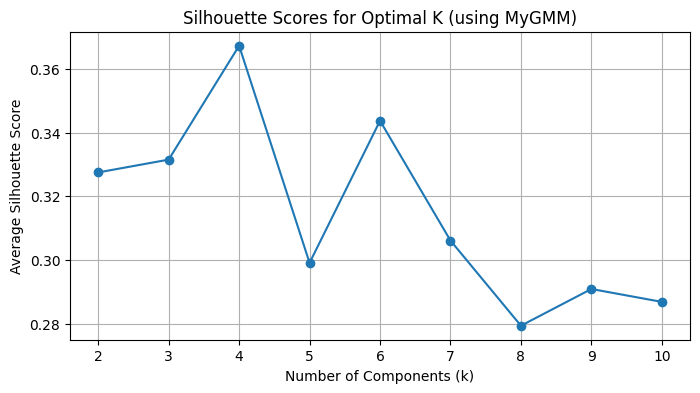

In [47]:
from sklearn.metrics import silhouette_score

silhouette_scores = []
# k_range is the same: range(2, 11)

print("\nRunning Silhouette Method with custom GMM...")
for k in k_range:
    # 1. Fit your custom MyGMM model
    gmm = MyGMM(k=k, max_iters=100, tol=1e-4)
    gmm.fit(scaled_features)
    
    # 2. Get definite cluster labels from your predict method
    labels = gmm.predict(scaled_features)
    
    # 3. Calculate and append the silhouette score
    silhouette = silhouette_score(scaled_features, labels)
    silhouette_scores.append(silhouette)
    
    print(f"  Silhouette Score for k={k}: {silhouette:.4f}")

# 4. Plot the Silhouette scores
plt.figure(figsize=(8, 4))
plt.plot(k_range, silhouette_scores, marker='o', linestyle='-')
plt.title('Silhouette Scores for Optimal K (using MyGMM)')
plt.xlabel('Number of Components (k)')
plt.ylabel('Average Silhouette Score')
plt.xticks(k_range)
plt.grid(True)
plt.show()

* Commentary on the Clusters (Silhouette Method)

    According to the Silhouette Method, the optimal number of clusters (or components) for this dataset is **k=4**.

    This conclusion is drawn by identifying the number of clusters that yields the **highest average silhouette score**. A higher score indicates that the resulting clusters are more dense, distinct, and well-separated from one another.

    * **Analysis of the Plot:** The graph shows a clear "peak" or maximum value. The average silhouette score rises from `k=2` and reaches its highest point at **k=4** (with a score of approximately 0.365).
    * **For k > 4:** The score drops significantly at `k=5` and continues to fluctuate at lower values. This suggests that forcing the data into more than four groups results in clusters that are less distinct and may have significant overlap.

    **What the Score Tells Us About the Clusters:**

    * A peak silhouette score of around **0.365** indicates a **reasonably good clustering structure**. While not a perfect score (which would be closer to 1.0), it is significantly positive, suggesting that the four clusters are meaningful.
    * This score implies that, on average, data points are considerably closer to the other points within their own cluster than they are to points in neighboring clusters. The clusters are distinct enough to be considered valid and well-separated.

    Therefore, the Silhouette Method strongly suggests that a model with **4 components** provides the best and most meaningful segmentation of the customer data.